In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

train_df = pd.read_csv("../data/training.csv")

In [2]:
#check for missing value
print("Missing values in Churn:", train_df["Churn"].isna().sum())

print("\nChurn value distribution:")
print(train_df["Churn"].value_counts(dropna=False))

Missing values in Churn: 1

Churn value distribution:
Churn
1.0    249999
0.0    190833
NaN         1
Name: count, dtype: int64


In [3]:
#as we found one we can safely drop that column
train_df = train_df.dropna(subset=["Churn"]).copy()

create features bellow that is independent and dependent(churn)
customer id is removed bcoz it is unnecessary


In [4]:
# Create independent features (X)
X = train_df.drop(columns=["CustomerID", "Churn"])

# Create dependent target (y)
y = train_df["Churn"]


print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (440832, 10)
Target shape: (440832,)


In [5]:
#separate numerical and categorical features
numerical_features = [
    "Age",
    "Tenure",
    "Usage Frequency",
    "Support Calls",
    "Payment Delay",
    "Total Spend",
    "Last Interaction"
]

categorical_features = [
    "Gender",
    "Subscription Type",
    "Contract Length"
]

In [6]:
# Numerical preprocessing
numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing methods
preprocessor = ColumnTransformer(transformers=[
    ("num", numerical_transformer, numerical_features),
    ("cat", categorical_transformer, categorical_features)
])


In [7]:
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Validation data:", X_val.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nValidation target distribution:")
print(y_val.value_counts(normalize=True) * 100)

Training data: (352665, 10)
Validation data: (88167, 10)

Training target distribution:
Churn
1.0    56.71076
0.0    43.28924
Name: proportion, dtype: float64

Validation target distribution:
Churn
1.0    56.710561
0.0    43.289439
Name: proportion, dtype: float64


In [8]:
#logistic regression model train
logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# Train the model
logistic_model.fit(X_train, y_train)

print("Logistic Regression training completed!")

Logistic Regression training completed!


In [9]:
#generate prediction
y_pred = logistic_model.predict(X_val)
y_prob = logistic_model.predict_proba(X_val)[:, 1]

In [10]:
accuracy = accuracy_score(y_val, y_pred)
precision = precision_score(y_val, y_pred)
recall = recall_score(y_val, y_pred)
f1 = f1_score(y_val, y_pred)
roc_auc = roc_auc_score(y_val, y_prob)

print("LOGISTIC REGRESSION PERFORMANCE")
print("--------------------------------")
print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1 Score  : {f1:.4f}")
print(f"ROC-AUC   : {roc_auc:.4f}")

LOGISTIC REGRESSION PERFORMANCE
--------------------------------
Accuracy  : 0.8934
Precision : 0.9234
Recall    : 0.8855
F1 Score  : 0.9040
ROC-AUC   : 0.9590


In [11]:
print(classification_report(
    y_val,
    y_pred,
    target_names=["Not Churned", "Churned"]
))

              precision    recall  f1-score   support

 Not Churned       0.86      0.90      0.88     38167
     Churned       0.92      0.89      0.90     50000

    accuracy                           0.89     88167
   macro avg       0.89      0.89      0.89     88167
weighted avg       0.89      0.89      0.89     88167



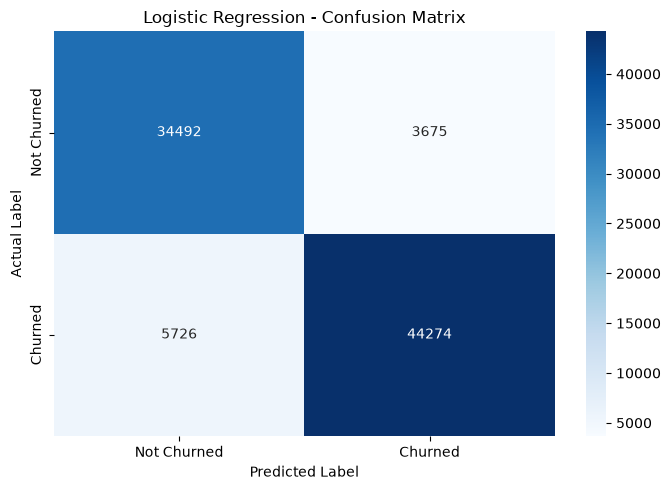

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_val, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not Churned", "Churned"],
    yticklabels=["Not Churned", "Churned"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Logistic Regression - Confusion Matrix")

plt.tight_layout()
plt.show()

above is the baseline model of logistic regression without adding any engineered attributes

In [13]:

# ==========================================
# FEATURE ENGINEERING
# ==========================================

# Calculate thresholds from training data only
usage_threshold = X_train["Usage Frequency"].median()
tenure_threshold = X_train["Tenure"].median()
support_threshold = X_train["Support Calls"].median()
delay_threshold = X_train["Payment Delay"].median()


def add_features(data):

    data = data.copy()

    # 1. Usage and Tenure Interaction
    data["Usage_Tenure_Interaction"] = (
        data["Usage Frequency"] * data["Tenure"]
    )

    # 2. Support Calls and Payment Delay Interaction
    data["Support_Payment_Risk"] = (
        data["Support Calls"] * data["Payment Delay"]
    )

    # 3. Low Usage + Low Tenure
    data["Low_Usage_Low_Tenure"] = (
        (data["Usage Frequency"] < usage_threshold) &
        (data["Tenure"] < tenure_threshold)
    ).astype(int)

    # 4. High Support Calls + High Payment Delay
    data["High_Support_High_Delay"] = (
        (data["Support Calls"] > support_threshold) &
        (data["Payment Delay"] > delay_threshold)
    ).astype(int)

    return data


# Apply to training and validation data
X_train_fe = add_features(X_train)
X_val_fe = add_features(X_val)

print("Feature engineering completed!")

print("Original features:", X_train.shape[1])
print("New features:", X_train_fe.shape[1])

print("\nNew attributes:")
display(X_train_fe.iloc[:, -4:].head())


Feature engineering completed!
Original features: 10
New features: 14

New attributes:


,Usage_Tenure_Interaction,Support_Payment_Risk,Low_Usage_Low_Tenure,High_Support_High_Delay
318331,1380.0,12.0,0,0
429062,731.0,15.0,0,0
60074,390.0,48.0,0,0
12759,207.0,240.0,0,1
357321,200.0,0.0,0,0


In [14]:

numerical_features_fe = numerical_features + [
    "Usage_Tenure_Interaction",
    "Support_Payment_Risk",
    "Low_Usage_Low_Tenure",
    "High_Support_High_Delay"
]

print("Total numerical features:", len(numerical_features_fe))
print(numerical_features_fe)


Total numerical features: 11
['Age', 'Tenure', 'Usage Frequency', 'Support Calls', 'Payment Delay', 'Total Spend', 'Last Interaction', 'Usage_Tenure_Interaction', 'Support_Payment_Risk', 'Low_Usage_Low_Tenure', 'High_Support_High_Delay']


In [15]:

# Numerical preprocessing
numerical_transformer_fe = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer_fe = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
preprocessor_fe = ColumnTransformer(transformers=[
    ("num", numerical_transformer_fe, numerical_features_fe),
    ("cat", categorical_transformer_fe, categorical_features)
])


In [16]:

# Create a separate Logistic Regression pipeline
logistic_model_fe = Pipeline(steps=[
    ("preprocessor", preprocessor_fe),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# Train using engineered features
logistic_model_fe.fit(X_train_fe, y_train)

print("Feature Engineered Logistic Regression training completed!")


Feature Engineered Logistic Regression training completed!


In [17]:

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

# Predictions
y_pred_fe = logistic_model_fe.predict(X_val_fe)

# Probability predictions
y_prob_fe = logistic_model_fe.predict_proba(X_val_fe)[:, 1]

print("LOGISTIC REGRESSION - FEATURE ENGINEERED")

print("\nAccuracy:",
      accuracy_score(y_val, y_pred_fe))

print("\nClassification Report:")
print(classification_report(y_val, y_pred_fe))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_pred_fe))

print("\nROC-AUC:",
      roc_auc_score(y_val, y_prob_fe))


LOGISTIC REGRESSION - FEATURE ENGINEERED

Accuracy: 0.8955731736363945

Classification Report:
              precision    recall  f1-score   support

         0.0       0.86      0.90      0.88     38167
         1.0       0.92      0.89      0.91     50000

    accuracy                           0.90     88167
   macro avg       0.89      0.90      0.89     88167
weighted avg       0.90      0.90      0.90     88167


Confusion Matrix:
[[34501  3666]
 [ 5541 44459]]

ROC-AUC: 0.9601654020488904


In [18]:

# Baseline predictions
y_pred_baseline = logistic_model.predict(X_val)

y_prob_baseline = logistic_model.predict_proba(X_val)[:, 1]

# Comparison
comparison = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"],

    "Baseline": [
        accuracy_score(y_val, y_pred_baseline),
        precision_score(y_val, y_pred_baseline, pos_label=1),
        recall_score(y_val, y_pred_baseline, pos_label=1),
        f1_score(y_val, y_pred_baseline, pos_label=1),
        roc_auc_score(y_val, y_prob_baseline)
    ],

    "Feature Engineered": [
        accuracy_score(y_val, y_pred_fe),
        precision_score(y_val, y_pred_fe, pos_label=1),
        recall_score(y_val, y_pred_fe, pos_label=1),
        f1_score(y_val, y_pred_fe, pos_label=1),
        roc_auc_score(y_val, y_prob_fe)
    ]
})

display(comparison.round(4))


,Metric,Baseline,Feature Engineered
0,Accuracy,0.8934,0.8956
1,Precision,0.9234,0.9238
2,Recall,0.8855,0.8892
3,F1-Score,0.9040,0.9062
4,ROC-AUC,0.9590,0.9602


In [19]:
results = []

results.append({
    "Model": "Logistic Regression - Baseline",
    "Accuracy": accuracy_score(y_val, y_pred_baseline),
    "Precision": precision_score(y_val, y_pred_baseline, pos_label=1),
    "Recall": recall_score(y_val, y_pred_baseline, pos_label=1),
    "F1-Score": f1_score(y_val, y_pred_baseline, pos_label=1),
    "ROC-AUC": roc_auc_score(y_val, y_prob_baseline)
})

results.append({
    "Model": "Logistic Regression - Feature Engineered",
    "Accuracy": accuracy_score(y_val, y_pred_fe),
    "Precision": precision_score(y_val, y_pred_fe, pos_label=1),
    "Recall": recall_score(y_val, y_pred_fe, pos_label=1),
    "F1-Score": f1_score(y_val, y_pred_fe, pos_label=1),
    "ROC-AUC": roc_auc_score(y_val, y_prob_fe)
})

results_df = pd.DataFrame(results)

display(results_df.round(4))
results_df.to_csv(
    "../data/logistic_regression_results.csv",
    index=False
)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression - Baseline,0.8934,0.9234,0.8855,0.9040,0.9590
1,Logistic Regression - Feature Engineered,0.8956,0.9238,0.8892,0.9062,0.9602


In [20]:
import joblib

joblib.dump(logistic_model, "../models/logisticRE_model.pkl")
joblib.dump(logistic_model_fe, "../models/logisticRE_fe_model.pkl")


['../models/logisticRE_fe_model.pkl']